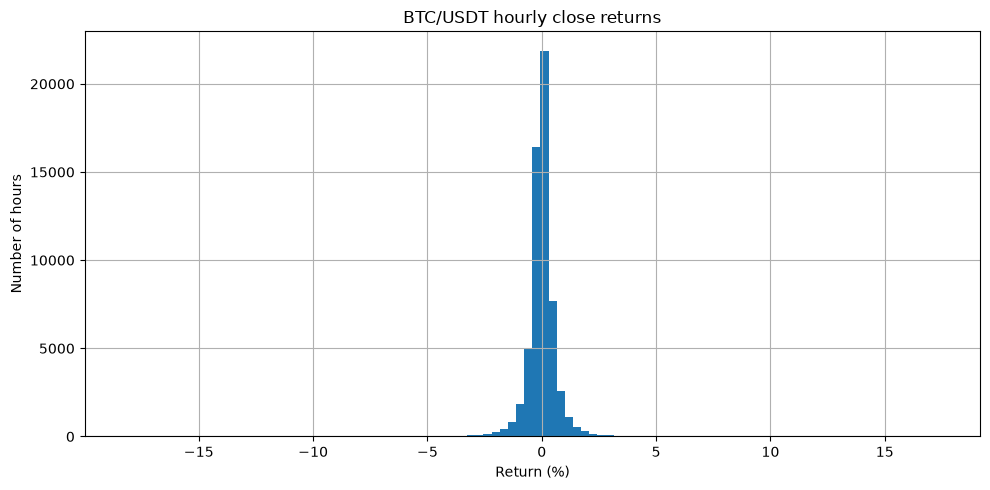

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "../data/raw/btcusdt_1h.csv",
    parse_dates=["timestamp"],
).sort_values("timestamp")

is_one_hour = df["timestamp"].diff() == pd.Timedelta(hours=1)

returns = (
    df["close"]
    .pct_change(fill_method=None)
    .where(is_one_hour)
    .dropna()
)

(returns * 100).hist(bins=100, figsize=(10, 5))
plt.title("BTC/USDT hourly close returns")
plt.xlabel("Return (%)")
plt.ylabel("Number of hours")
plt.tight_layout()
plt.show()

In [2]:
import pandas as pd

demo = pd.DataFrame({
    "timestamp": pd.to_datetime([
        "2026-01-01 10:00",
        "2026-01-01 11:00",
        "2026-01-01 13:00",  # 12:00 wali candle missing hai
    ], utc=True),
    "close": [100, 102, 105],
})

demo["next_timestamp"] = demo["timestamp"].shift(-1)
demo["next_close"] = demo["close"].shift(-1)
demo["gap_is_one_hour"] = (
    demo["next_timestamp"] - demo["timestamp"]
) == pd.Timedelta(hours=1)

demo["next_return"] = (
    demo["next_close"] / demo["close"] - 1
).where(demo["gap_is_one_hour"])

demo

,timestamp,close,next_timestamp,next_close,gap_is_one_hour,next_return
0,2026-01-01 10:00:00+00:00,100,2026-01-01 11:00:00+00:00,102.0,True,0.02
1,2026-01-01 11:00:00+00:00,102,2026-01-01 13:00:00+00:00,105.0,False,NaN
2,2026-01-01 13:00:00+00:00,105,NaT,NaN,False,NaN


In [3]:
btc = pd.read_csv(
    "../data/raw/btcusdt_1h.csv",
    parse_dates=["timestamp"],
).sort_values("timestamp").reset_index(drop=True)

btc["next_timestamp"] = btc["timestamp"].shift(-1)
btc["next_close"] = btc["close"].shift(-1)

btc["gap_is_one_hour"] = (
    btc["next_timestamp"] - btc["timestamp"]
) == pd.Timedelta(hours=1)

btc[[
    "timestamp",
    "close",
    "next_timestamp",
    "next_close",
    "gap_is_one_hour",
]].head(8)

,timestamp,close,next_timestamp,next_close,gap_is_one_hour
0,2020-01-01 00:00:00+00:00,7177.02,2020-01-01 01:00:00+00:00,7216.27,True
1,2020-01-01 01:00:00+00:00,7216.27,2020-01-01 02:00:00+00:00,7242.85,True
2,2020-01-01 02:00:00+00:00,7242.85,2020-01-01 03:00:00+00:00,7225.01,True
3,2020-01-01 03:00:00+00:00,7225.01,2020-01-01 04:00:00+00:00,7217.27,True
4,2020-01-01 04:00:00+00:00,7217.27,2020-01-01 05:00:00+00:00,7224.21,True
5,2020-01-01 05:00:00+00:00,7224.21,2020-01-01 06:00:00+00:00,7225.62,True
6,2020-01-01 06:00:00+00:00,7225.62,2020-01-01 07:00:00+00:00,7209.83,True
7,2020-01-01 07:00:00+00:00,7209.83,2020-01-01 08:00:00+00:00,7200.64,True


In [1]:
import pandas as pd

example = pd.DataFrame({
    "current_close": [100, 100, 100],
    "next_close": [102, 100, 98],
})

example["next_return"] = (
    example["next_close"] / example["current_close"] - 1
)

example["label"] = (example["next_return"] > 0).astype(int)

example


,current_close,next_close,next_return,label
0,100,102,0.02,1
1,100,100,0.00,0
2,100,98,-0.02,0


In [2]:
# Sabse bade hourly gains aur losses dikhayein
largest_gains = returns.nlargest(5)
largest_losses = returns.nsmallest(5)

print("Largest hourly gains:")
print(df.loc[largest_gains.index, ["timestamp", "close"]].assign(return_pct=largest_gains * 100))

print("\nLargest hourly losses:")
print(df.loc[largest_losses.index, ["timestamp", "close"]].assign(return_pct=largest_losses * 100))

Largest hourly gains:
                     timestamp     close  return_pct
1723 2020-03-13 02:00:00+00:00   4848.71   17.383989
1790 2020-03-15 21:00:00+00:00   5903.77   13.831094
9446 2021-01-29 08:00:00+00:00  36240.24   12.315896
9690 2021-02-08 12:00:00+00:00  42984.07    9.032754
1973 2020-03-23 12:00:00+00:00   6323.91    8.225161

Largest hourly losses:
                      timestamp     close  return_pct
1707  2020-03-12 10:00:00+00:00   6014.90  -18.211473
1720  2020-03-12 23:00:00+00:00   4800.00  -17.279887
1722  2020-03-13 01:00:00+00:00   4130.64  -11.259109
1791  2020-03-15 22:00:00+00:00   5367.76   -9.079114
12083 2021-05-19 12:00:00+00:00  35234.62   -8.954470


In [5]:
btc["next_timestamp"] = btc["timestamp"].shift(-1)
btc["next_close"] = btc["close"].shift(-1)

btc["gap_is_one_hour"] = (
    btc["next_timestamp"] - btc["timestamp"]
) == pd.Timedelta(hours=1)

btc["next_return"] = (
    btc["next_close"] / btc["close"] - 1
).where(btc["gap_is_one_hour"])

btc[[
    "timestamp",
    "close",
    "next_timestamp",
    "next_close",
    "gap_is_one_hour",
    "next_return",
]].head(8)

,timestamp,close,next_timestamp,next_close,gap_is_one_hour,next_return
0,2020-01-01 00:00:00+00:00,7177.02,2020-01-01 01:00:00+00:00,7216.27,True,0.005469
1,2020-01-01 01:00:00+00:00,7216.27,2020-01-01 02:00:00+00:00,7242.85,True,0.003683
2,2020-01-01 02:00:00+00:00,7242.85,2020-01-01 03:00:00+00:00,7225.01,True,-0.002463
3,2020-01-01 03:00:00+00:00,7225.01,2020-01-01 04:00:00+00:00,7217.27,True,-0.001071
4,2020-01-01 04:00:00+00:00,7217.27,2020-01-01 05:00:00+00:00,7224.21,True,0.000962
5,2020-01-01 05:00:00+00:00,7224.21,2020-01-01 06:00:00+00:00,7225.62,True,0.000195
6,2020-01-01 06:00:00+00:00,7225.62,2020-01-01 07:00:00+00:00,7209.83,True,-0.002185
7,2020-01-01 07:00:00+00:00,7209.83,2020-01-01 08:00:00+00:00,7200.64,True,-0.001275


In [6]:
btc.loc[:5, [
    "timestamp",
    "close",
    "next_timestamp",
    "next_close",
    "gap_is_one_hour",
    "next_return",
]].to_string(index=False)

'                timestamp   close            next_timestamp  next_close  gap_is_one_hour  next_return\n2020-01-01 00:00:00+00:00 7177.02 2020-01-01 01:00:00+00:00     7216.27             True     0.005469\n2020-01-01 01:00:00+00:00 7216.27 2020-01-01 02:00:00+00:00     7242.85             True     0.003683\n2020-01-01 02:00:00+00:00 7242.85 2020-01-01 03:00:00+00:00     7225.01             True    -0.002463\n2020-01-01 03:00:00+00:00 7225.01 2020-01-01 04:00:00+00:00     7217.27             True    -0.001071\n2020-01-01 04:00:00+00:00 7217.27 2020-01-01 05:00:00+00:00     7224.21             True     0.000962\n2020-01-01 05:00:00+00:00 7224.21 2020-01-01 06:00:00+00:00     7225.62             True     0.000195'

In [7]:
gap_rows = btc.loc[
    btc["next_timestamp"] - btc["timestamp"] != pd.Timedelta(hours=1),
    ["timestamp", "close", "next_timestamp", "next_close",
     "gap_is_one_hour", "next_return"],
]

gap_rows.head(5).to_string(index=False)


'                timestamp    close            next_timestamp  next_close  gap_is_one_hour  next_return\n2020-02-09 01:00:00+00:00  9938.90 2020-02-09 03:00:00+00:00    10052.63            False          NaN\n2020-02-19 11:00:00+00:00 10148.93 2020-02-19 17:00:00+00:00    10158.94            False          NaN\n2020-03-04 09:00:00+00:00  8795.06 2020-03-04 11:00:00+00:00     8717.12            False          NaN\n2020-04-25 01:00:00+00:00  7480.78 2020-04-25 04:00:00+00:00     7518.42            False          NaN\n2020-06-28 01:00:00+00:00  8971.80 2020-06-28 05:00:00+00:00     8961.59            False          NaN'

In [8]:
btc["target_up"] = (btc["next_return"] > 0).astype("Int64")

btc[[
    "timestamp",
    "close",
    "next_close",
    "next_return",
    "target_up",
]].head(8).to_string(index=False)


'                timestamp   close  next_close  next_return  target_up\n2020-01-01 00:00:00+00:00 7177.02     7216.27     0.005469          1\n2020-01-01 01:00:00+00:00 7216.27     7242.85     0.003683          1\n2020-01-01 02:00:00+00:00 7242.85     7225.01    -0.002463          0\n2020-01-01 03:00:00+00:00 7225.01     7217.27    -0.001071          0\n2020-01-01 04:00:00+00:00 7217.27     7224.21     0.000962          1\n2020-01-01 05:00:00+00:00 7224.21     7225.62     0.000195          1\n2020-01-01 06:00:00+00:00 7225.62     7209.83    -0.002185          0\n2020-01-01 07:00:00+00:00 7209.83     7200.64    -0.001275          0'

In [9]:
print("UP (1):", (btc["target_up"] == 1).sum())
print("NOT UP (0):", (btc["target_up"] == 0).sum())
print("No target:", btc["target_up"].isna().sum())
print("Total candles:", len(btc))

UP (1): 30250
NOT UP (0): 29424
No target: 0
Total candles: 59674


In [10]:
check = btc.loc[
    btc["gap_is_one_hour"] == False,
    ["timestamp", "next_timestamp", "gap_is_one_hour",
     "next_return", "target_up"],
]

print(check.head(5).to_string(index=False))
print("Rows without a one-hour next candle:", len(check))

                timestamp            next_timestamp  gap_is_one_hour  next_return  target_up
2020-02-09 01:00:00+00:00 2020-02-09 03:00:00+00:00            False          NaN          0
2020-02-19 11:00:00+00:00 2020-02-19 17:00:00+00:00            False          NaN          0
2020-03-04 09:00:00+00:00 2020-03-04 11:00:00+00:00            False          NaN          0
2020-04-25 01:00:00+00:00 2020-04-25 04:00:00+00:00            False          NaN          0
2020-06-28 01:00:00+00:00 2020-06-28 05:00:00+00:00            False          NaN          0
Rows without a one-hour next candle: 16


In [11]:
btc["target_up"] = pd.Series(pd.NA, index=btc.index, dtype="Int64")

valid_target = btc["gap_is_one_hour"]

btc.loc[valid_target, "target_up"] = (
    btc.loc[valid_target, "next_return"] > 0
).astype("Int64")

print("UP (1):", (btc["target_up"] == 1).sum())
print("NOT UP (0):", (btc["target_up"] == 0).sum())
print("No target:", btc["target_up"].isna().sum())
print("Total candles:", len(btc))

UP (1): 30250
NOT UP (0): 29408
No target: 16
Total candles: 59674


In [12]:
valid_labels = btc["target_up"].dropna()

print("Valid target rows:", len(valid_labels))
print("UP proportion:", (valid_labels == 1).mean())
print("NOT UP proportion:", (valid_labels == 0).mean())

Valid target rows: 59658
UP proportion: 0.5070568909450535
NOT UP proportion: 0.49294310905494654


In [13]:
btc["return_1h"] = (
    btc["close"] / btc["close"].shift(1) - 1
).where(
    btc["timestamp"].diff() == pd.Timedelta(hours=1)
)

btc[[
    "timestamp",
    "close",
    "return_1h",
    "next_return",
    "target_up",
]].head(8).to_string(index=False)

'                timestamp   close  return_1h  next_return  target_up\n2020-01-01 00:00:00+00:00 7177.02        NaN     0.005469          1\n2020-01-01 01:00:00+00:00 7216.27   0.005469     0.003683          1\n2020-01-01 02:00:00+00:00 7242.85   0.003683    -0.002463          0\n2020-01-01 03:00:00+00:00 7225.01  -0.002463    -0.001071          0\n2020-01-01 04:00:00+00:00 7217.27  -0.001071     0.000962          1\n2020-01-01 05:00:00+00:00 7224.21   0.000962     0.000195          1\n2020-01-01 06:00:00+00:00 7225.62   0.000195    -0.002185          0\n2020-01-01 07:00:00+00:00 7209.83  -0.002185    -0.001275          0'

In [14]:
previous_3h_close = btc["close"].shift(3)
three_hour_span = btc["timestamp"] - btc["timestamp"].shift(3)

btc["return_3h"] = (
    btc["close"] / previous_3h_close - 1
).where(three_hour_span == pd.Timedelta(hours=3))

btc[[
    "timestamp",
    "close",
    "return_3h",
    "target_up",
]].head(8).to_string(index=False)

'                timestamp   close  return_3h  target_up\n2020-01-01 00:00:00+00:00 7177.02        NaN          1\n2020-01-01 01:00:00+00:00 7216.27        NaN          1\n2020-01-01 02:00:00+00:00 7242.85        NaN          0\n2020-01-01 03:00:00+00:00 7225.01   0.006687          0\n2020-01-01 04:00:00+00:00 7217.27   0.000139          1\n2020-01-01 05:00:00+00:00 7224.21  -0.002574          1\n2020-01-01 06:00:00+00:00 7225.62   0.000084          0\n2020-01-01 07:00:00+00:00 7209.83  -0.001031          0'

In [15]:
for hours in [6, 24]:
    old_close = btc["close"].shift(hours)
    actual_span = btc["timestamp"] - btc["timestamp"].shift(hours)

    btc[f"return_{hours}h"] = (
        btc["close"] / old_close - 1
    ).where(actual_span == pd.Timedelta(hours=hours))

btc[[
    "timestamp",
    "close",
    "return_1h",
    "return_3h",
    "return_6h",
    "return_24h",
    "target_up",
]].iloc[23:27].to_string(index=False)

'                timestamp   close  return_1h  return_3h  return_6h  return_24h  target_up\n2020-01-01 23:00:00+00:00 7200.85   0.000397  -0.004958  -0.004972         NaN          1\n2020-01-02 00:00:00+00:00 7211.02   0.001412  -0.003062  -0.004095    0.004737          0\n2020-01-02 01:00:00+00:00 7190.99  -0.002778  -0.000972  -0.005324   -0.003503          0\n2020-01-02 02:00:00+00:00 7169.02  -0.003055  -0.004420  -0.009356   -0.010194          0'

In [19]:
# Har row mein is candle aur pichhli candle ke beech ka waqt
hour_gap = btc["timestamp"].diff()

# Return ki pichhli 24 values ka standard deviation
btc["volatility_24h"] = btc["return_1h"].rolling(
    window=24,
    min_periods=24,
).std()

# Pichhle 24 transitions mein har gap theek 1 ghanta tha?
has_24_consecutive_hours = (
    hour_gap.eq(pd.Timedelta(hours=1))
    .rolling(window=24, min_periods=24)
    .sum()
    .eq(24)
)

# Agar window mein missing-hour gap ho, volatility feature khaali rakho
btc.loc[~has_24_consecutive_hours, "volatility_24h"] = float("nan")

# Pehli 24 rows ke aas-paas result dekho
print(
    btc[["timestamp", "return_1h", "volatility_24h", "target_up"]]
    .iloc[20:30]
    .to_string(index=False)
)

                timestamp  return_1h  volatility_24h  target_up
2020-01-01 20:00:00+00:00   0.001003             NaN          0
2020-01-01 21:00:00+00:00  -0.000492             NaN          0
2020-01-01 22:00:00+00:00  -0.004864             NaN          1
2020-01-01 23:00:00+00:00   0.000397             NaN          1
2020-01-02 00:00:00+00:00   0.001412        0.002248          0
2020-01-02 01:00:00+00:00  -0.002778        0.002027          0
2020-01-02 02:00:00+00:00  -0.003055        0.001938          0
2020-01-02 03:00:00+00:00  -0.005497        0.002163          1
2020-01-02 04:00:00+00:00   0.001767        0.002210          0
2020-01-02 05:00:00+00:00  -0.000459        0.002190          0


In [16]:
btc["next_timestamp"] = btc["timestamp"].shift(-1)
btc["next_close"] = btc["close"].shift(-1)

btc["gap_is_one_hour"] = (
    btc["next_timestamp"] - btc["timestamp"]
) == pd.Timedelta(hours=1)

btc["next_return"] = (
    btc["next_close"] / btc["close"] - 1
).where(btc["gap_is_one_hour"])

btc[[
    "timestamp",
    "close",
    "next_timestamp",
    "next_close",
    "gap_is_one_hour",
    "next_return",
]].head(8)

,timestamp,close,next_timestamp,next_close,gap_is_one_hour,next_return
0,2020-01-01 00:00:00+00:00,7177.02,2020-01-01 01:00:00+00:00,7216.27,True,0.005469
1,2020-01-01 01:00:00+00:00,7216.27,2020-01-01 02:00:00+00:00,7242.85,True,0.003683
2,2020-01-01 02:00:00+00:00,7242.85,2020-01-01 03:00:00+00:00,7225.01,True,-0.002463
3,2020-01-01 03:00:00+00:00,7225.01,2020-01-01 04:00:00+00:00,7217.27,True,-0.001071
4,2020-01-01 04:00:00+00:00,7217.27,2020-01-01 05:00:00+00:00,7224.21,True,0.000962
5,2020-01-01 05:00:00+00:00,7224.21,2020-01-01 06:00:00+00:00,7225.62,True,0.000195
6,2020-01-01 06:00:00+00:00,7225.62,2020-01-01 07:00:00+00:00,7209.83,True,-0.002185
7,2020-01-01 07:00:00+00:00,7209.83,2020-01-01 08:00:00+00:00,7200.64,True,-0.001275


## Observation

Most hourly BTC returns are clustered close to 0%. Larger positive and negative moves occur less often. This chart describes historical data; it does not predict future returns.